# 01 — PaySim Mobile Money Data Mining & Exploratory Analysis (Part B)

**Course:** DSA 4050 · **Topic:** Real-Time Mobile Money & Credit Card Fraud Detection

### Presentation Objectives
1. Inspect the PaySim transaction log structure (`step`, `type`, `amount`, origin/destination balances, `isFraud`, `isFlaggedFraud`).
2. Quantify the **extreme class imbalance** (< 0.5% overall fraud) and demonstrate why naive rule engines (`isFlaggedFraud`) fail.
3. Prove domain-level structural properties: **100% of fraud occurs in `TRANSFER` and `CASH_OUT`**.
4. Uncover behavioral attack signatures: **overnight fraud spikes (00:00–05:00)** and **100% origin-account emptying**.

In [1]:
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_prep import load_raw_or_sample

df, source_desc = load_raw_or_sample()
meta = json.loads((ROOT / 'data' / 'processed' / 'metadata.json').read_text())
print('Dataset loaded:', source_desc)
print(f"Total rows: {len(df):,} | Fraud cases: {int(df['isFraud'].sum()):,} ({100*df['isFraud'].mean():.3f}%)")
df.head(8)

Dataset loaded: Calibrated PaySim Dataset (250,000 rows)
Total rows: 250,000 | Fraud cases: 1,215 (0.486%)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,5710.28,C100000000,0.00,0.00,M200000000,0.00,0.00,0,0
1,1,CASH_IN,48367.04,C100000001,287366.69,335733.73,C200000001,0.00,0.00,0,0
2,1,TRANSFER,677375.14,C100000002,0.00,0.00,C200000002,0.00,677375.14,0,0
3,1,CASH_OUT,659538.32,C100000003,1754458.31,1094919.99,C200000003,0.00,659538.32,0,0
4,1,PAYMENT,4726.24,C100000004,34126.92,29400.68,M200000004,0.00,0.00,0,0
5,1,TRANSFER,463265.46,C100000005,1130331.40,667065.94,C200000005,389604.18,852869.64,0,0
6,1,PAYMENT,3160.83,C100000006,36541.98,33381.15,M200000006,0.00,0.00,0,0
7,1,CASH_IN,85168.90,C100000007,0.00,85168.90,C200000007,206895.52,121726.62,0,0


## 1. Fraud Distribution Across Transaction Types
Every mobile money transaction falls into one of five channels (`CASH_OUT`, `PAYMENT`, `CASH_IN`, `TRANSFER`, `DEBIT`). Mining the table below reveals that **fraud is strictly confined to `TRANSFER` and `CASH_OUT`**—where attackers first transfer stolen funds to a mule account and immediately cash out.

,type,total_tx,fraud_tx,mean_amount,median_amount,fraud_rate_pct
1,CASH_OUT,"87,863",615,"$185,477.72","$109,588.43",0.700%
3,PAYMENT,"84,412",0,"$12,121.56","$6,651.41",0.000%
0,CASH_IN,"55,018",0,"$148,452.97","$98,810.92",0.000%
4,TRANSFER,"21,059",600,"$543,768.69","$247,008.62",2.849%
2,DEBIT,"1,648",0,"$5,855.83","$3,542.66",0.000%


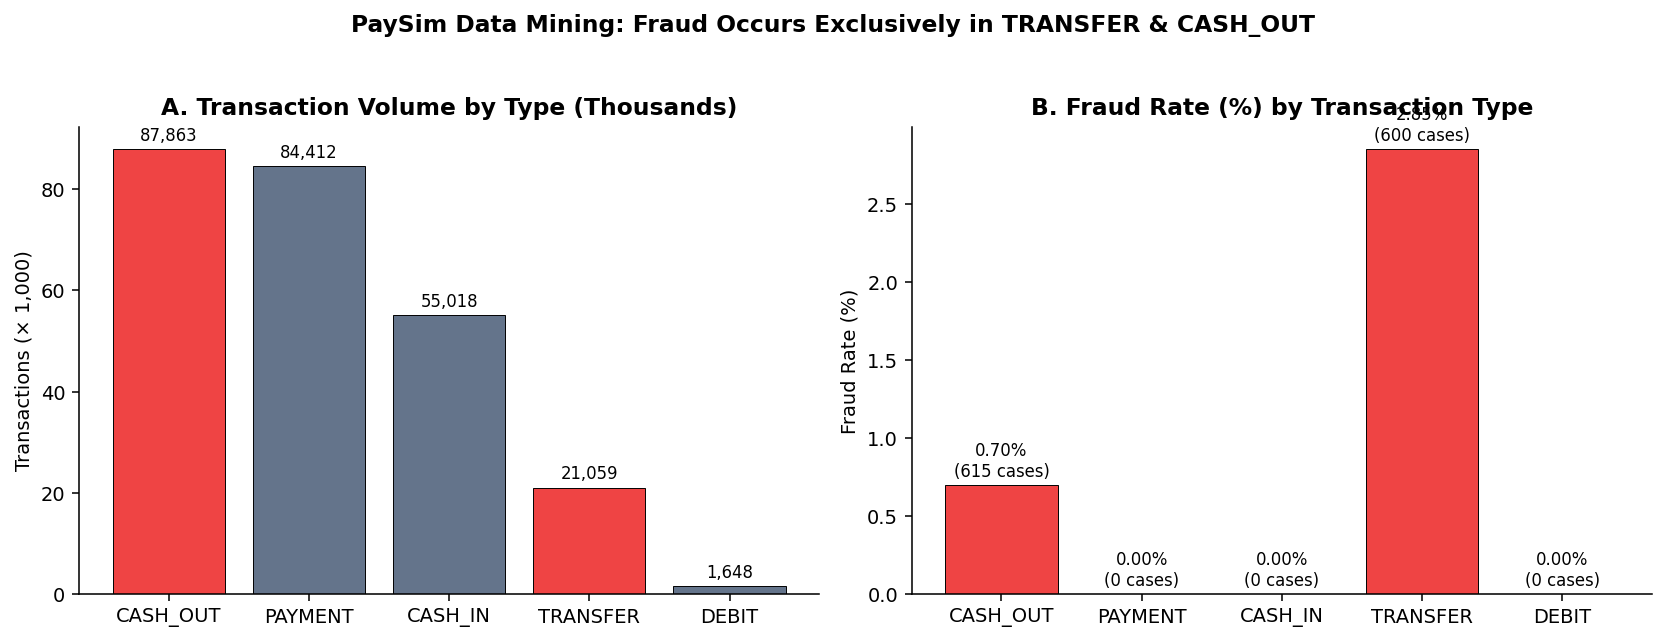

In [2]:
type_df = pd.DataFrame(meta['type_summary']).sort_values('total_tx', ascending=False)
display(type_df.style.format({'total_tx': '{:,}', 'fraud_tx': '{:,}', 'mean_amount': '${:,.2f}', 'median_amount': '${:,.2f}', 'fraud_rate_pct': '{:.3f}%'}))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'fig1_fraud_by_type.png')))

## 2. Failure of the Legacy Rule-Based Engine (`isFlaggedFraud`)
PaySim includes a built-in static rule column `isFlaggedFraud` that triggers when a single `TRANSFER` exceeds $200,000 under specific zero-balance conditions. Let's inspect how many actual frauds it catches:

In [3]:
ct = pd.crosstab(df['isFraud'], df['isFlaggedFraud'], rownames=['Actual isFraud'], colnames=['Rule isFlaggedFraud'])
recall_rule = 100.0 * meta['flagged_tp'] / max(meta['total_fraud'], 1)
print(f'Rule Engine Recall: {recall_rule:.2f}% ({meta["flagged_tp"]} caught out of {meta["total_fraud"]} frauds)')
ct

Rule Engine Recall: 0.08% (1 caught out of 1215 frauds)


Rule isFlaggedFraud,0,1
Actual isFraud,,
0,248785,0
1,1214,1


## 3. Nocturnal Fraud Velocity & Account-Draining Signatures
While legitimate mobile money traffic drops sharply between **00:00 and 05:00**, automated account-takeover scripts continue unabated—causing the hourly fraud rate to spike overnight. Furthermore, fraudulent transactions disproportionately empty **100% of the victim's origin balance (`amount / oldbalanceOrg ≈ 1.0`)**.

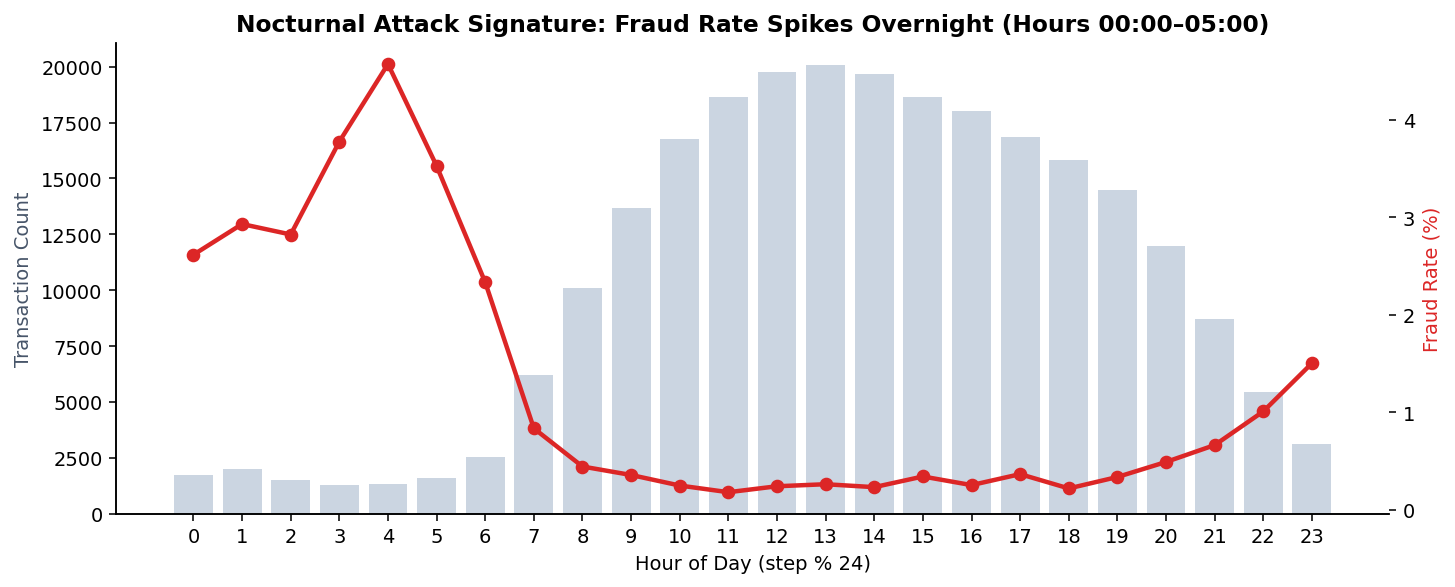

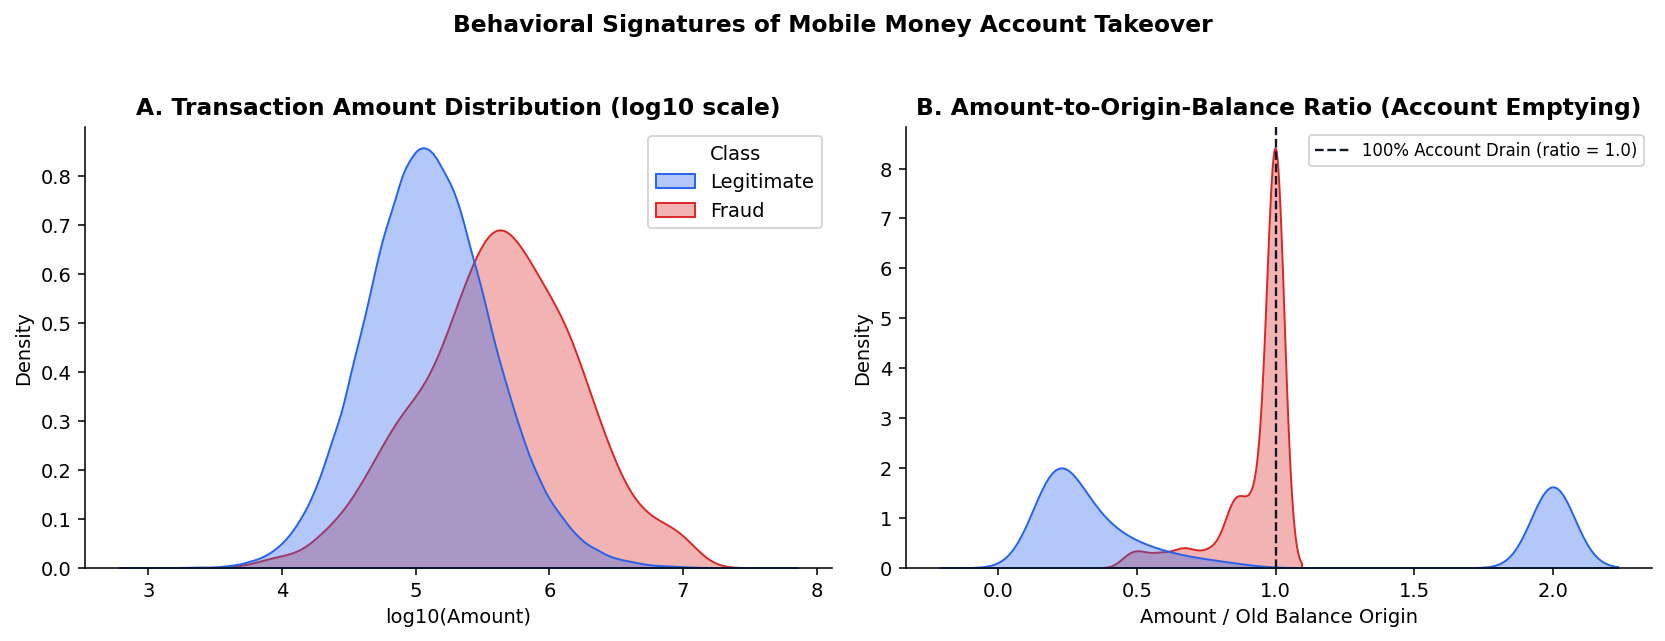

In [4]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'fig2_hourly_fraud_pattern.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'fig3_amount_and_drain.png')))